,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


K-Means Inertia: 65.57
K-Means Silhouette Score: 0.5547
Agglomerative Silhouette Score: 0.5538


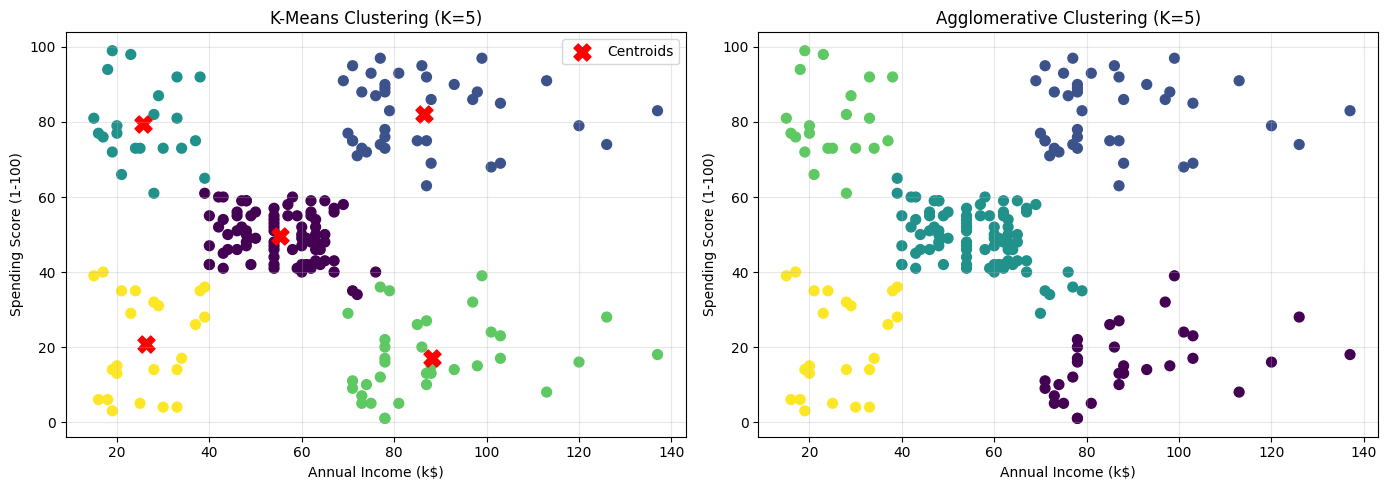


K-Means Strengths: Fast, efficient, and scalable.
K-Means Weaknesses: Requires K in advance and is sensitive to outliers.
Agglomerative Strengths: Reveals hierarchical relationships between clusters.
Agglomerative Weaknesses: Computationally expensive and cannot undo merges.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Load dataset
df = pd.read_csv("/content/Mall_Customers.csv")
display(df.head())

# Select and scale features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
y_means = kmeans.fit_predict(X_scaled)

# Agglomerative clustering
hc = AgglomerativeClustering(n_clusters=5)
y_hc = hc.fit_predict(X_scaled)

# Evaluation metrics
print("K-Means Inertia:", round(kmeans.inertia_, 2))
print("K-Means Silhouette Score:",
      round(silhouette_score(X_scaled, y_means), 4))
print("Agglomerative Silhouette Score:",
      round(silhouette_score(X_scaled, y_hc), 4))

# Convert centroids to original scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# Visualize clusters
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# K-Means plot
ax1.scatter(X[:, 0], X[:, 1], c=y_means, cmap="viridis", s=50)
ax1.scatter(centroids[:, 0], centroids[:, 1],
            c="red", marker="X", s=150, label="Centroids")
ax1.set_title("K-Means Clustering (K=5)")
ax1.set_xlabel("Annual Income (k$)")
ax1.set_ylabel("Spending Score (1-100)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Agglomerative plot
ax2.scatter(X[:, 0], X[:, 1], c=y_hc, cmap="viridis", s=50)
ax2.set_title("Agglomerative Clustering (K=5)")
ax2.set_xlabel("Annual Income (k$)")
ax2.set_ylabel("Spending Score (1-100)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Comparison
print("\nK-Means Strengths: Fast, efficient, and scalable.")
print("K-Means Weaknesses: Requires K in advance and is sensitive to outliers.")
print("Agglomerative Strengths: Reveals hierarchical relationships between clusters.")
print("Agglomerative Weaknesses: Computationally expensive and cannot undo merges.")